# Experiment 10: Pet Adoption Analysis Using Machine Learning

**Objective:** Analyze pet adoption data, visualize patterns, and predict adoption status using Decision Tree, Support Vector Machine (SVM), and Random Forest classifiers.

> **Dataset note:** `pet_adoption.csv` is a synthetic teaching dataset generated for this mini project. Use it to demonstrate the workflow; do not present its patterns as real-world findings.


## Step 1: Import the required libraries

If a library is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn` in a separate notebook cell, then restart the kernel if necessary.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load the dataset

Keep `pet_adoption.csv` in the same folder as this notebook. If it is in another folder, update the file path below.


In [2]:
df = pd.read_csv("pet_adoption.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (300, 11)


,Pet_ID,Animal_Type,Breed,Age_Years,Age_Group,Gender,Location,Vaccinated,Health_Status,Adoption_Status,Adoption_Days
0,P0001,Dog,Mixed,6,Adult,Female,Coimbatore,Yes,Recovering,Not Adopted,NaN
1,P0002,Cat,Tabby,0,Baby,Female,Bengaluru,Yes,Healthy,Adopted,45.0
2,P0003,Cat,Siamese,0,Baby,Male,Coimbatore,Yes,Healthy,Adopted,12.0
3,P0004,Dog,Golden Retriever,0,Baby,Male,Hyderabad,Yes,Healthy,Adopted,48.0
4,P0005,Dog,Mixed,0,Baby,Female,Chennai,Yes,Healthy,Adopted,33.0


## Step 3: Explore and understand the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\\nSummary of numeric columns:")
display(df.describe())

print("\\nAdoption status counts:")
display(df["Adoption_Status"].value_counts())


Column names:
['Pet_ID', 'Animal_Type', 'Breed', 'Age_Years', 'Age_Group', 'Gender', 'Location', 'Vaccinated', 'Health_Status', 'Adoption_Status', 'Adoption_Days']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Pet_ID           300 non-null    str    
 1   Animal_Type      300 non-null    str    
 2   Breed            300 non-null    str    
 3   Age_Years        300 non-null    int64  
 4   Age_Group        300 non-null    str    
 5   Gender           300 non-null    str    
 6   Location         300 non-null    str    
 7   Vaccinated       300 non-null    str    
 8   Health_Status    300 non-null    str    
 9   Adoption_Status  300 non-null    str    
 10  Adoption_Days    242 non-null    float64
dtypes: float64(1), int64(1), str(9)
memory usage: 41.1 KB
\nMissing values per column:


,Missing Values
Pet_ID,0
Animal_Type,0
Breed,0
Age_Years,0
Age_Group,0
Gender,0
Location,0
Vaccinated,0
Health_Status,0
Adoption_Status,0


\nSummary of numeric columns:


,Age_Years,Adoption_Days
count,300.0000,242.000000
mean,3.4100,32.041322
std,3.3575,17.308716
min,0.0000,1.000000
25%,1.0000,18.000000
50%,2.0000,33.500000
75%,5.0000,47.000000
max,14.0000,60.000000


\nAdoption status counts:


Adoption_Status
Adopted        242
Not Adopted     58
Name: count, dtype: int64

## Step 4: Clean the data

In [4]:
# Remove duplicate rows and duplicate pet IDs, if any.
df = df.drop_duplicates()
df = df.drop_duplicates(subset="Pet_ID")

# Adoption_Days is only available for adopted pets. It is not used as a predictor.
# Missing Adoption_Days for pets that were not adopted is expected, not an error.
print("Shape after duplicate removal:", df.shape)
print("Missing Adoption_Days values are expected for pets that were not adopted.")


Shape after duplicate removal: (300, 11)
Missing Adoption_Days values are expected for pets that were not adopted.


## Step 5: Exploratory Data Analysis (EDA)

These charts show the distribution in this sample dataset. Since the data is synthetic, describe these as sample-data observations.


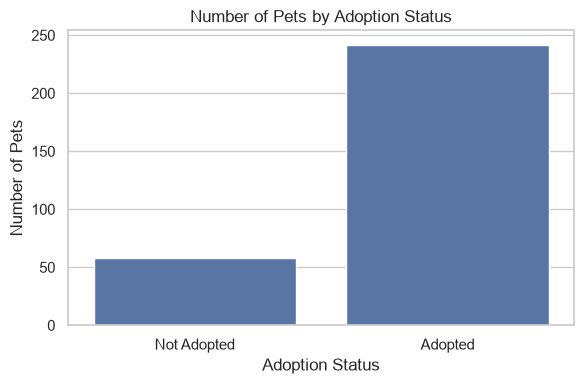

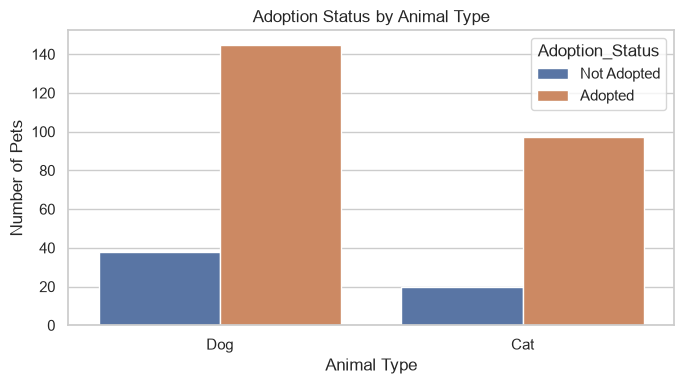

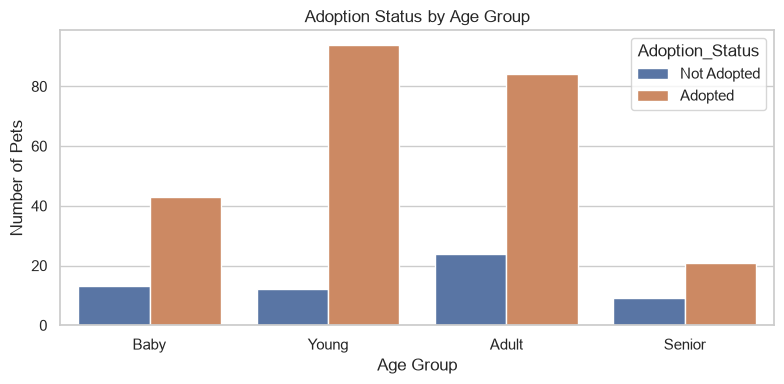

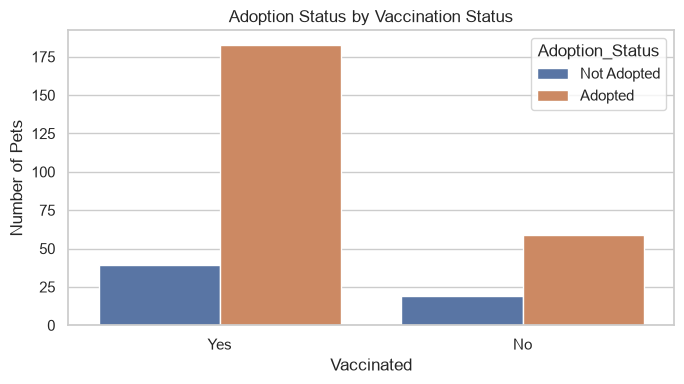

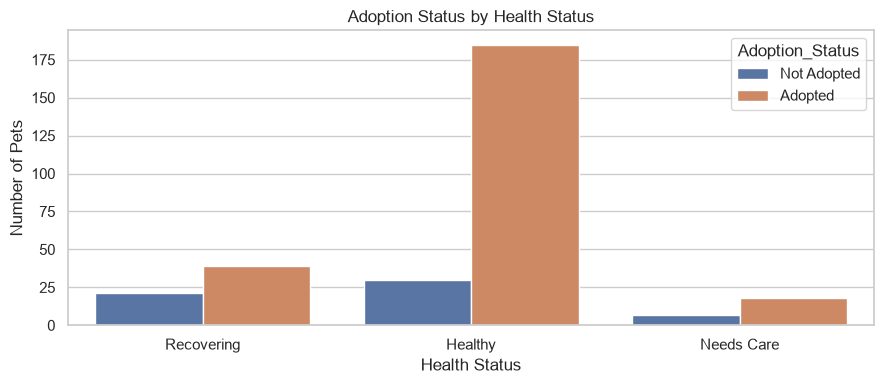

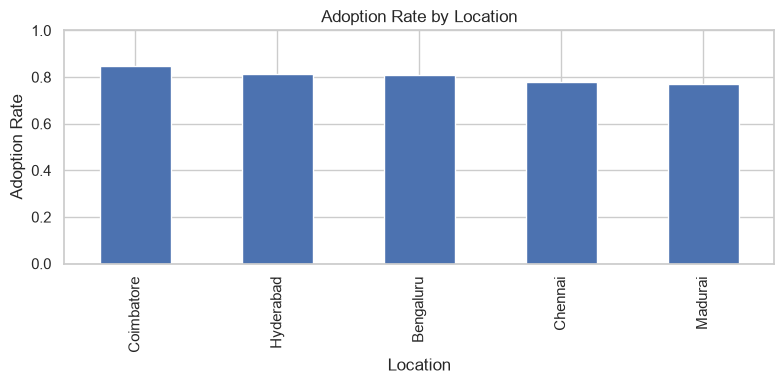

Adoption rate by location:


,Adoption_Rate
Location,
Coimbatore,0.847222
Hyderabad,0.814815
Bengaluru,0.810345
Chennai,0.779661
Madurai,0.771930


In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Adoption_Status")
plt.title("Number of Pets by Adoption Status")
plt.xlabel("Adoption Status")
plt.ylabel("Number of Pets")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Animal_Type", hue="Adoption_Status")
plt.title("Adoption Status by Animal Type")
plt.xlabel("Animal Type")
plt.ylabel("Number of Pets")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Age_Group", hue="Adoption_Status",
              order=["Baby", "Young", "Adult", "Senior"])
plt.title("Adoption Status by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Pets")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Vaccinated", hue="Adoption_Status")
plt.title("Adoption Status by Vaccination Status")
plt.xlabel("Vaccinated")
plt.ylabel("Number of Pets")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="Health_Status", hue="Adoption_Status")
plt.title("Adoption Status by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Number of Pets")
plt.tight_layout()
plt.show()

adoption_rate = (
    df.assign(Adopted_Flag=(df["Adoption_Status"] == "Adopted").astype(int))
      .groupby("Location")["Adopted_Flag"].mean()
      .sort_values(ascending=False)
)
adoption_rate.plot(kind="bar", figsize=(8, 4))
plt.title("Adoption Rate by Location")
plt.xlabel("Location")
plt.ylabel("Adoption Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Adoption rate by location:")
display(adoption_rate.rename("Adoption_Rate").to_frame())


## Step 6: Prepare features and target

**Target:** `Adoption_Status`  
**Excluded columns:** `Pet_ID` (identifier) and `Adoption_Days` (known only after adoption, which could cause data leakage).

We use the other pet characteristics as input features. A pipeline handles missing values, encoding, and scaling safely.


In [6]:
target = "Adoption_Status"
drop_columns = ["Pet_ID", "Adoption_Days", target]

X = df.drop(columns=drop_columns)
y = df[target]

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("\\nTarget distribution:")
display(y.value_counts(normalize=True).rename("Proportion").to_frame())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Categorical features: ['Animal_Type', 'Breed', 'Age_Group', 'Gender', 'Location', 'Vaccinated', 'Health_Status']
Numeric features: ['Age_Years']
\nTarget distribution:


/var/folders/mx/zfzwj0pn5m79td_4n4cr4yy80000gn/T/ipykernel_50264/1724149926.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


,Proportion
Adoption_Status,
Adopted,0.806667
Not Adopted,0.193333


Training records: 240
Testing records: 60


## Step 7: Train Decision Tree, SVM, and Random Forest

In [7]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False)
display(results_df.round(3))


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
1,SVM,0.617,0.549,0.573,0.536
0,Decision Tree,0.767,0.527,0.510,0.495
2,Random Forest,0.650,0.433,0.438,0.435


## Step 8: Evaluate the best model

Best model based on macro F1-score: SVM
\nClassification report:
              precision    recall  f1-score   support

     Adopted       0.84      0.65      0.73        48
 Not Adopted       0.26      0.50      0.34        12

    accuracy                           0.62        60
   macro avg       0.55      0.57      0.54        60
weighted avg       0.72      0.62      0.65        60



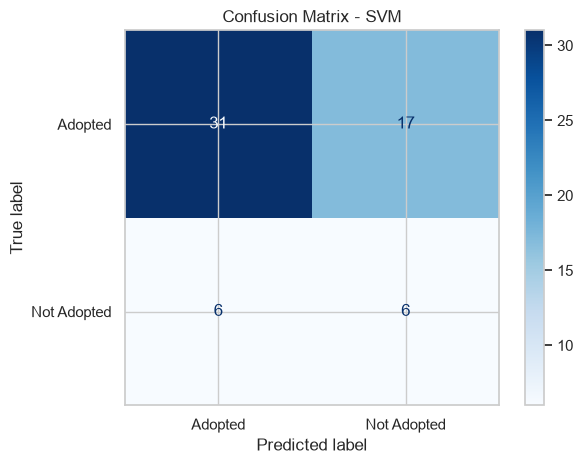

In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model based on macro F1-score:", best_model_name)
print("\\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

cm = confusion_matrix(y_test, best_predictions, labels=best_model.classes_)
display_labels = best_model.classes_

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


## Step 9: Hyperparameter tuning with Grid Search and Cross-Validation

This step tunes a Random Forest model. It may take a little longer than the previous cells.


In [9]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro F1-score:", round(grid_search.best_score_, 3))

tuned_predictions = grid_search.best_estimator_.predict(X_test)
print("\\nTuned Random Forest test results:")
print(classification_report(y_test, tuned_predictions, zero_division=0))


Best parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best cross-validation macro F1-score: 0.613
\nTuned Random Forest test results:
              precision    recall  f1-score   support

     Adopted       0.76      0.67      0.71        48
 Not Adopted       0.11      0.17      0.13        12

    accuracy                           0.57        60
   macro avg       0.44      0.42      0.42        60
weighted avg       0.63      0.57      0.60        60



## Step 10: Predict adoption for a new pet

Edit the sample pet details and run this cell. The prediction is only an educational model output, not a guarantee of adoption.


In [10]:
new_pet = pd.DataFrame([{
    "Animal_Type": "Dog",
    "Breed": "Labrador",
    "Age_Years": 1,
    "Age_Group": "Young",
    "Gender": "Female",
    "Location": "Chennai",
    "Vaccinated": "Yes",
    "Health_Status": "Healthy"
}])

prediction = grid_search.best_estimator_.predict(new_pet)[0]
print("Predicted adoption status:", prediction)

if hasattr(grid_search.best_estimator_, "predict_proba"):
    probabilities = grid_search.best_estimator_.predict_proba(new_pet)[0]
    probability_table = pd.DataFrame({
        "Class": grid_search.best_estimator_.classes_,
        "Predicted Probability": probabilities
    })
    display(probability_table)


Predicted adoption status: Adopted


,Class,Predicted Probability
0,Adopted,0.831201
1,Not Adopted,0.168799


## Step 11: Conclusion

After running all cells, write your conclusion using the actual metrics printed in your notebook. Compare the three baseline models and the tuned Random Forest using macro F1-score and the classification report. Discuss the sample EDA charts, mention any limitations, and state that the dataset is synthetic.

**Suggested conclusion template:**

> In this mini project, pet adoption data was explored and preprocessed using Python. Visualizations were created to examine adoption status across animal type, age group, vaccination status, health status, and location. Decision Tree, SVM, and Random Forest classifiers were trained and evaluated using a train-test split. Grid Search with 5-fold cross-validation was used to tune Random Forest hyperparameters. The model with the best evaluation results on this run was identified. Since the dataset is synthetic and limited in size, the findings are illustrative and should be validated using real shelter data before practical use.


## Troubleshooting

- **FileNotFoundError:** Put `pet_adoption.csv` in the same folder as this notebook, or update the path in Step 2.
- **ModuleNotFoundError:** Install the missing package with `!pip install package_name`, then restart the kernel.
- **Different results:** Model metrics can vary if you change the data, random seed, or settings.
- **Before submission:** Run the notebook from top to bottom and save it with outputs.
